# Data Cleaning and Preparation
This notebook turns combined_dataset.csv into one clean row per movie with the target success (worldwide revenue at least 2.5 times the production budget). Only steps that do not learn from the data are done here. Imputation and encoding are fit later on the training data only, so that no information from the test period leaks into the model.

### Setup
Budgets in this data range from $1 to over $600 million, and revenues reach almost $3 billion. With equal-width histogram bars, nearly every movie would fall into the first one or two bars, which would hide the small values that the budget and revenue floors are meant to catch. The budget and revenue histograms therefore use a log scale, and `log_bins` spaces the bar edges evenly on that scale, with four bars for every factor of 10 from $1 to $10 billion.

In [1]:
# Packages
import pandas as pd
import matplotlib.pyplot as plt

# One color for all single-series charts
BLUE = "#2a78d6"

# Histogram bin edges on a log scale: 10^0, 10^0.25, 10^0.5, ... up to 10^10
log_bins = []
for i in range(0, 41):
    log_bins.append(10 ** (i / 4))

### Step 1 Load the combined data
The combined file has one row per movie and director pair, so co-directed movies appear more than once.

In [2]:
# Step 1: Load the combined TMDB + IMDb data (one row per movie-director pair)
combined = pd.read_csv(
    "../data/combined_dataset.csv",
    dtype={"imdb_id": "string", "nconst": "string", "collection_id": "Int64", "startYear": "Int64"},
)
print("Combined rows (movie-director pairs):", len(combined))
print("Unique movies:", combined["tmdb_id"].nunique())

Combined rows (movie-director pairs): 14824
Unique movies: 13276


### Step 2 Collapse to one row per movie
The model predicts one outcome per movie, so each movie must appear exactly once. Otherwise co-directed movies would be counted twice. The IMDb director IDs are kept as a "|" separated list for the director history features.

In [3]:
# Collapse to one row per movie
# Co-directed movies have one row per director, so join their IMDb director IDs and names with "|"
director_info = combined.groupby("tmdb_id").agg(
    imdb_director_ids=("nconst", "|".join),         # IMDb director IDs, used later for director history
    imdb_directors=("director_imdb", "|".join),     # IMDb director names, for reading only
    imdb_director_count=("nconst", "nunique"),      # number of directors
).reset_index()

# Keeps the first row of each movie for all movie-level columns, then attach the director info
movies = combined.drop(columns=["nconst", "director_imdb"]).drop_duplicates(subset="tmdb_id")
movies = movies.merge(director_info, on="tmdb_id", how="left", validate="one_to_one")

print("Movies (one row each):", len(movies))
print("tmdb_id is unique:", movies["tmdb_id"].is_unique)

Movies (one row each): 13276
tmdb_id is unique: True


### Step 3 First look with .info() and .describe()
`.info()` shows the column types and non-missing counts. `.describe()` shows the spread of the numeric columns. Both reveal problems to fix, such as `release_date` stored as text and budget, revenue, and runtime values of 0.

In [4]:
# First look at structure and data types
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 13276 entries, 0 to 13275
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   tmdb_id               13276 non-null  int64  
 1   imdb_id               13276 non-null  string 
 2   title_tmdb            13276 non-null  str    
 3   release_date          13276 non-null  str    
 4   budget                13276 non-null  int64  
 5   revenue               13276 non-null  int64  
 6   runtime               13276 non-null  int64  
 7   genres                13276 non-null  str    
 8   original_language     13276 non-null  str    
 9   popularity            13276 non-null  float64
 10  production_companies  13218 non-null  str    
 11  director_tmdb         13276 non-null  str    
 12  top_cast              13271 non-null  str    
 13  vote_count            13276 non-null  int64  
 14  vote_average          13276 non-null  float64
 15  collection_id         2713 non

In [5]:
# Summary statistics for the numeric columns (budget and revenue in USD, runtime in minutes)
movies.describe().round(2)

,tmdb_id,budget,revenue,runtime,popularity,vote_count,vote_average,collection_id,startYear,imdb_director_count
count,13276.00,1.327600e+04,1.327600e+04,13276.00,13276.00,13276.00,13276.00,2713.0,13276.0,13276.00
mean,283298.88,1.923937e+07,5.166539e+07,106.06,5.97,1583.37,6.46,458056.41,2010.37,1.12
std,354896.96,3.708804e+07,1.450108e+08,19.43,6.02,3096.61,0.79,473415.86,9.62,0.75
min,5.00,0.000000e+00,0.000000e+00,0.00,0.01,100.00,2.00,10.0,1974.0,1.00
25%,13531.75,0.000000e+00,0.000000e+00,94.00,2.83,252.00,5.94,87258.0,2003.0,1.00
50%,75626.50,4.000000e+06,3.741898e+06,103.00,4.21,499.50,6.50,280504.0,2011.0,1.00
75%,474364.25,2.200000e+07,3.536189e+07,115.00,6.76,1434.00,7.00,721111.0,2018.0,1.00
max,1589891.00,6.588000e+08,2.942178e+09,467.00,113.47,41669.00,9.10,1802417.0,2025.0,36.00


### Step 4 Fix data types and add date features
`release_date` must be a real date for the chronological train and test split. Release year and month are known before release, so they are valid predictors.

In [6]:
# Fix data types
movies["release_date"] = pd.to_datetime(movies["release_date"])   # text to a real date

# Pre-release date features
movies["release_year"] = movies["release_date"].dt.year
movies["release_month"] = movies["release_date"].dt.month

print(movies[["release_date", "release_year", "release_month"]].dtypes)
print("Release dates from", movies["release_date"].min().date(), "to", movies["release_date"].max().date())

release_date     datetime64[us]
release_year              int32
release_month             int32
dtype: object
Release dates from 1990-01-12 to 2025-12-28


### Step 5 Missing values and zeros
TMDB stores an unreported budget, revenue, or runtime as 0 rather than as missing, so zeros are counted separately. A missing `collection_id` is expected, because it means the movie is not part of a collection.

In [7]:
# Missing values per column (only columns with at least one missing value)
missing = movies.isna().sum()
missing = missing[missing > 0]
print(missing)

# Zeros in budget and revenue mean "not reported", not a real $0
print("\nbudget == 0:", (movies["budget"] == 0).sum())
print("revenue == 0:", (movies["revenue"] == 0).sum())
print("runtime == 0:", (movies["runtime"] == 0).sum())

production_companies       58
top_cast                    5
collection_id           10563
collection_name         10563
us_certification         2864
dtype: int64

budget == 0: 5439
revenue == 0: 4112
runtime == 0: 8


### Step 6 Franchise flag
TMDB assigns collections after the fact, so the first movie of a franchise also belongs to a collection only because it later had sequels. Using collection membership directly would leak the outcome. `is_sequel` is therefore 1 only when an earlier-released movie in the same collection exists, using TMDB dates on both sides. It is computed before any rows are dropped, because an earlier part counts even if its budget is unknown. One limitation is that movies released before 1990 are not in the data, so a sequel to a pre-1990 original is counted as a first film.

In [8]:
# Franchise flag (before any rows are dropped)
# is_sequel = 1 only if an earlier-released movie in the same collection is in the data.
# Uses TMDB release dates on both sides, and all movies (not just ones with budget data),
# because knowing an earlier part exists is pre-release information.
first_in_collection = movies.groupby("collection_id")["release_date"].transform("min")
movies["is_sequel"] = (movies["release_date"] > first_in_collection).astype(int)   # missing collection gives 0

print("Movies in a collection:", movies["collection_id"].notna().sum())
print("Sequels (an earlier part exists):", movies["is_sequel"].sum())
print("First films of a collection (not counted as sequels):", (movies["collection_id"].notna() & (movies["is_sequel"] == 0)).sum())

Movies in a collection: 2713
Sequels (an earlier part exists): 1243
First films of a collection (not counted as sequels): 1470


### Step 7 Drop movies without a reported budget or revenue
The target compares revenue with budget, so it cannot be calculated when either value is unknown. These movies are dropped rather than filled in, since any filled value would invent the outcome.

In [9]:
#  Drop movies with no reported budget or revenue
# The target needs both numbers, and 0 here means missing rather than a true $0
before = len(movies)
movies = movies[(movies["budget"] > 0) & (movies["revenue"] > 0)].copy()
print("Dropped for budget or revenue == 0:", before - len(movies))
print("Movies left:", len(movies))

Dropped for budget or revenue == 0: 6245
Movies left: 7031


### Step 8 and 9 Budget floor
The histogram uses a log scale because budgets range from $1 to over $600 million. The smallest budgets include clear unit errors, such as a budget of $5 for a movie with $12 million in revenue. Following the project rule, budgets under $1M are removed. This also removes some real low-budget movies, which is a limitation to state in the report.

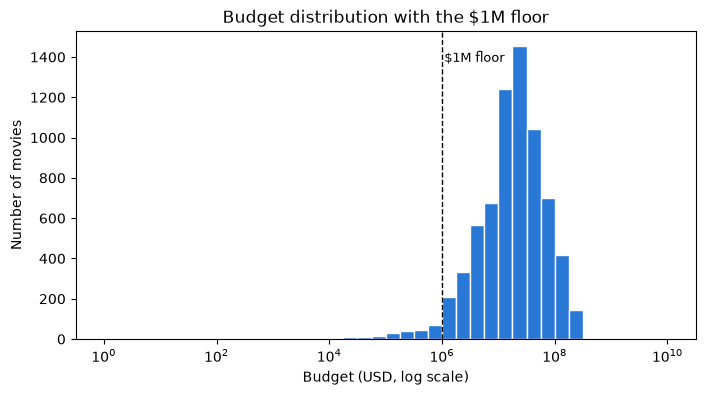

,title_tmdb,release_year,budget,revenue
11540,The Quiet Girl,2022,1,6
12111,The Flood,2023,2,25
6479,Red Dog,2011,5,13
8844,The Beatles: Eight Days a Week - The Touring Y...,2016,5,12283800
5326,Hero Wanted,2008,6,10
110,My Blue Heaven,1990,6,23
12747,Trust,2024,8,1
4392,The Notorious Bettie Page,2006,90,1410778
5606,Rampage,2009,120,428
4340,10 Items or Less,2006,400,1


In [10]:
# Look at the low end of budget before choosing a floor
# Log scale, because budgets range from $1 to hundreds of millions
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(movies["budget"], bins=log_bins, color=BLUE, edgecolor="white")
ax.set_xscale("log")
ax.axvline(1_000_000, color="black", linestyle="--", linewidth=1)
ax.text(1_100_000, ax.get_ylim()[1] * 0.9, "$1M floor", fontsize=9)
ax.set_xlabel("Budget (USD, log scale)")
ax.set_ylabel("Number of movies")
ax.set_title("Budget distribution with the $1M floor")
plt.show()

# Examples of the smallest budgets
movies.sort_values("budget")[["title_tmdb", "release_year", "budget", "revenue"]].head(10)

In [11]:
# Apply the $1M budget floor (project rule)
# It removes unit errors such as "5" for $5,000,000, but also some real low-budget movies
BUDGET_FLOOR = 1_000_000
print("Budgets under $1,000:", (movies["budget"] < 1_000).sum())
print("Budgets from $1,000 to under $1M:", ((movies["budget"] >= 1_000) & (movies["budget"] < BUDGET_FLOOR)).sum())
before = len(movies)
movies = movies[movies["budget"] >= BUDGET_FLOOR].copy()
print("Dropped for budget under $1M:", before - len(movies))
print("Movies left:", len(movies))

Budgets under $1,000: 11
Budgets from $1,000 to under $1M: 230
Dropped for budget under $1M: 241
Movies left: 6790


### Step 10 and 11 Revenue floor
Revenue has the same kind of unit errors at the low end, such as $1 or $16 for movies with multi-million budgets. These would be labeled as failures because of a data error rather than poor performance, so revenues under $1,000 are removed.

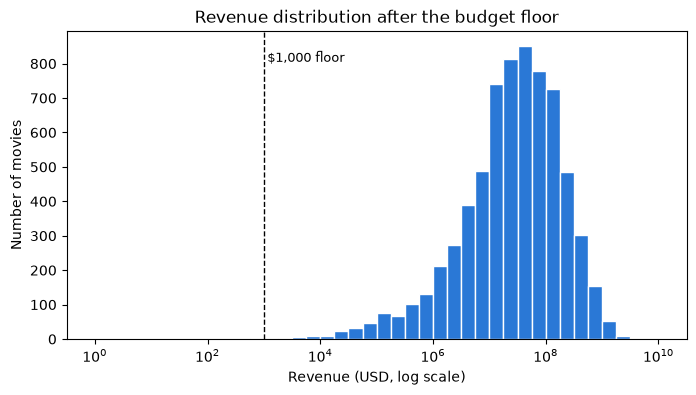

,title_tmdb,release_year,budget,revenue
12727,Enea,2024,8178032,1
12546,Daaaaaalí!,2024,6700000,3
12426,Memoir of a Snail,2024,4350000,7
12522,Monsieur Aznavour,2024,28000000,16
4764,Ben X,2007,1500000,27
1627,Trojan War,1997,15000000,309
5196,Far Cry,2008,30000000,743
11484,Sniper: The White Raven,2022,1000000,881
65,Bride of Re-Animator,1990,2500000,1215
11855,Society of the Snow,2023,65500000,1281


In [12]:
# Look at the low end of revenue
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(movies["revenue"], bins=log_bins, color=BLUE, edgecolor="white")
ax.set_xscale("log")
ax.axvline(1_000, color="black", linestyle="--", linewidth=1)
ax.text(1_150, ax.get_ylim()[1] * 0.9, "$1,000 floor", fontsize=9)
ax.set_xlabel("Revenue (USD, log scale)")
ax.set_ylabel("Number of movies")
ax.set_title("Revenue distribution after the budget floor")
plt.show()

# Examples of the smallest revenues
movies.sort_values("revenue")[["title_tmdb", "release_year", "budget", "revenue"]].head(10)

In [13]:
#  Drop revenues under $1,000 (likely unit errors such as $1 or $16 on a multi-million budget)
REVENUE_FLOOR = 1_000
before = len(movies)
movies = movies[movies["revenue"] >= REVENUE_FLOOR].copy()
print("Dropped for revenue under $1,000:", before - len(movies))
print("Movies left:", len(movies))

Dropped for revenue under $1,000: 8
Movies left: 6782


### Step 12 Create the target
`success` is 1 when worldwide revenue is at least 2.5 times the production budget. The revenue to budget ratio is a comparison within the same release, so inflation adjustment is not needed for the target. About 36% of movies are successes, a moderate imbalance, so models should be judged on precision, recall, and F1 rather than accuracy alone.

success
0    4339
1    2443
Name: count, dtype: int64
Success rate: 36.0 %


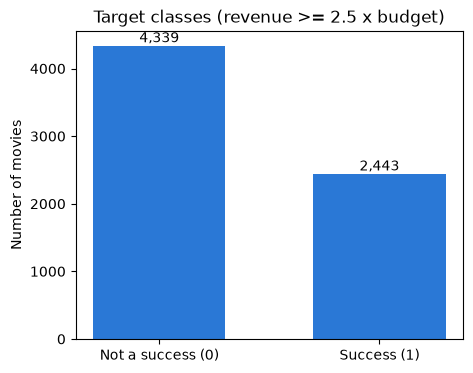

In [14]:
# Create the target
# success = 1 when worldwide revenue is at least 2.5 times the production budget
movies["revenue_to_budget"] = movies["revenue"] / movies["budget"]   # analysis only, never a predictor
movies["success"] = (movies["revenue"] >= 2.5 * movies["budget"]).astype(int)

counts = movies["success"].value_counts().sort_index()
print(counts)
print("Success rate:", round(movies["success"].mean() * 100, 1), "%")

# Class balance
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Not a success (0)", "Success (1)"], counts.values, color=BLUE, width=0.6)
for i in range(len(counts)):
    ax.text(i, counts.values[i], f"{counts.values[i]:,}", ha="center", va="bottom")
ax.set_ylabel("Number of movies")
ax.set_title("Target classes (revenue >= 2.5 x budget)")
plt.show()

### Step 13 Movies and success rate by release year
The split is chronological, so the success rate must be checked over time. A test period with a very different success rate would change how the model is evaluated. The 2025 movies have a success rate close to the overall rate, which supports keeping them.

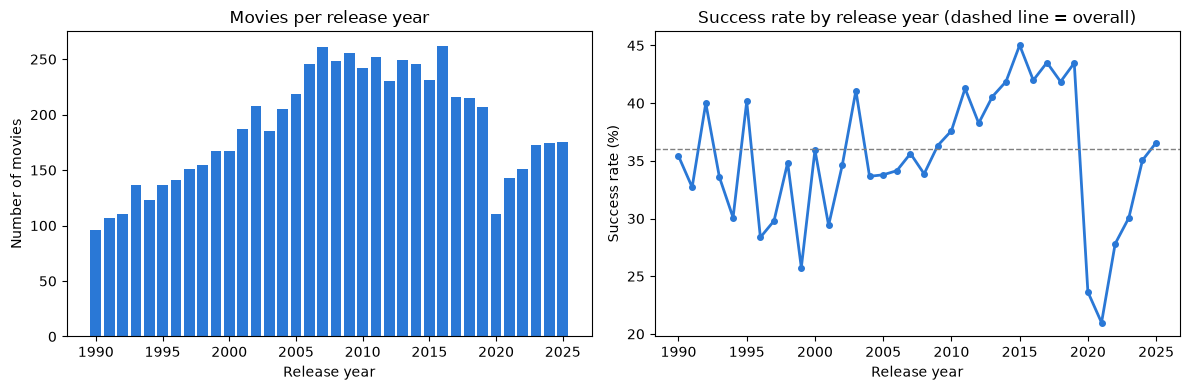

,size,mean
release_year,,
2020,110,0.236
2021,143,0.210
2022,151,0.278
2023,173,0.301
2024,174,0.351
2025,175,0.366


In [15]:
# Movies and success rate by release year (two charts, not one chart with two axes)
by_year = movies.groupby("release_year")["success"].agg(["size", "mean"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(by_year.index, by_year["size"], color=BLUE)
axes[0].set_xlabel("Release year")
axes[0].set_ylabel("Number of movies")
axes[0].set_title("Movies per release year")

axes[1].plot(by_year.index, by_year["mean"] * 100, color=BLUE, linewidth=2, marker="o", markersize=4)
axes[1].axhline(movies["success"].mean() * 100, color="gray", linestyle="--", linewidth=1)
axes[1].set_xlabel("Release year")
axes[1].set_ylabel("Success rate (%)")
axes[1].set_title("Success rate by release year (dashed line = overall)")
plt.tight_layout()
plt.show()

by_year.tail(6).round(3)

### Step 14 Runtime
A runtime of 0 means the runtime was not reported, so it is set to missing rather than kept as 0. It is filled in later inside the model pipeline using the training data only, which avoids leaking information from the test period.

In [16]:
#  Runtime
# runtime == 0 means "not reported"; set it to missing.
# It is filled in later inside the model pipeline, using training data only.
print("runtime == 0:", (movies["runtime"] == 0).sum())
movies.loc[movies["runtime"] == 0, "runtime"] = pd.NA
print(movies["runtime"].describe().round(1))

# The longest runtimes (listed below) are kept, since they are plausible feature-film lengths
movies.sort_values("runtime", ascending=False)[["title_tmdb", "runtime"]].head(5)

runtime == 0: 3
count    6779.0
mean      109.8
std        19.8
min        63.0
25%        96.0
50%       106.0
75%       120.0
max       254.0
Name: runtime, dtype: float64


,title_tmdb,runtime
6365,Kill Bill: The Whole Bloody Affair,254.0
685,Gettysburg,254.0
1310,Hamlet,242.0
2541,Lagaan: Once Upon a Time in India,233.0
12709,Pushpa 2 - The Rule,225.0


### Step 15 US certification
The rating is assigned before release, so it is a valid predictor. A missing value means TMDB has no US rating, while "NR" means the movie was released as Not Rated. They are kept as two separate categories instead of dropping these movies.

us_certification
R          2969
PG-13      2048
PG          856
Unknown     537
NR          214
G           138
NC-17        20
Name: count, dtype: int64


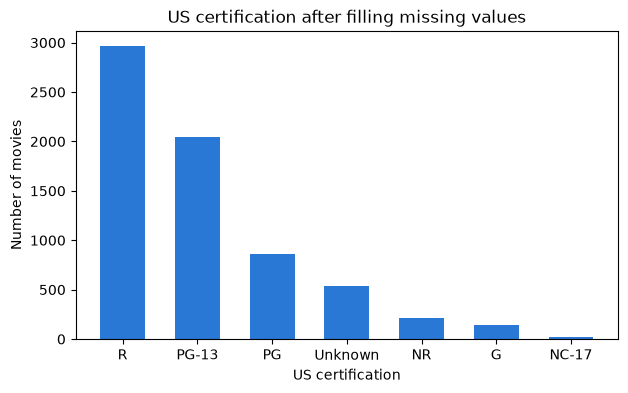

In [17]:
# US certification
# Missing means TMDB has no US rating; "NR" means the movie was released as Not Rated.
# Keep them as separate categories rather than dropping those movies.
movies["us_certification"] = movies["us_certification"].fillna("Unknown")
cert_counts = movies["us_certification"].value_counts()
print(cert_counts)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(cert_counts.index, cert_counts.values, color=BLUE, width=0.6)
ax.set_xlabel("US certification")
ax.set_ylabel("Number of movies")
ax.set_title("US certification after filling missing values")
plt.show()

### Step 16 Small text gaps
A few movies have no production companies or cast listed. They become an empty list so that later text features do not fail.

In [18]:
#  Small text gaps
# Missing production companies or cast become an empty list ("") so text features do not break
for column in ["production_companies", "top_cast"]:
    print(column, "missing before:", movies[column].isna().sum())
    movies[column] = movies[column].fillna("")

production_companies missing before: 2
top_cast missing before: 1


### Step 17 Compare IMDb and TMDB years
IMDb `startYear` and the TMDB release year agree for most movies and differ by one year for some. The few large gaps are kept. To avoid mixing sources, history features compare TMDB dates only with TMDB dates and IMDb years only with IMDb years.

In [19]:
#  Check the two sources' years
# IMDb startYear and the TMDB release year usually agree. The few large gaps are kept, and
# history features compare TMDB dates only with TMDB dates and IMDb years only with IMDb years.
year_gap = movies["startYear"] - movies["release_year"]
print(year_gap.value_counts().sort_index())
movies.loc[year_gap.abs() >= 3, ["title_tmdb", "release_date", "startYear"]]

-7       1
-5       1
-2       9
-1     252
0     6517
1        2
Name: count, dtype: Int64


,title_tmdb,release_date,startYear
6365,Kill Bill: The Whole Bloody Affair,2011-03-27,2004
13126,Hamilton,2025-09-05,2020


### Step 18 Leakage columns and final check
Revenue, the revenue to budget ratio, popularity, vote count, and vote average describe the movie after release or are built from the target, so they must never be predictors for the current movie. They stay in the file for analysis and for features built from earlier movies only. The rows are sorted by release date to prepare for the chronological split.

In [20]:
# Columns that must never be predictors (known only after release, or derived from the target)
LEAKAGE_COLUMNS = ["revenue", "revenue_to_budget", "popularity", "vote_count", "vote_average"]
print("Keep for analysis only, never as predictors:", LEAKAGE_COLUMNS)

# Final check
movies = movies.sort_values("release_date").reset_index(drop=True)   # chronological order for the later split
movies.info()

Keep for analysis only, never as predictors: ['revenue', 'revenue_to_budget', 'popularity', 'vote_count', 'vote_average']
<class 'pandas.DataFrame'>
RangeIndex: 6782 entries, 0 to 6781
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   tmdb_id               6782 non-null   int64         
 1   imdb_id               6782 non-null   string        
 2   title_tmdb            6782 non-null   str           
 3   release_date          6782 non-null   datetime64[us]
 4   budget                6782 non-null   int64         
 5   revenue               6782 non-null   int64         
 6   runtime               6779 non-null   float64       
 7   genres                6782 non-null   str           
 8   original_language     6782 non-null   str           
 9   popularity            6782 non-null   float64       
 10  production_companies  6782 non-null   str           
 11  director_tmdb         6

In [21]:
movies.describe().round(2)

,tmdb_id,release_date,budget,revenue,runtime,popularity,vote_count,vote_average,collection_id,startYear,imdb_director_count,release_year,release_month,is_sequel,revenue_to_budget,success
count,6782.00,6782,6.782000e+03,6.782000e+03,6779.00,6782.00,6782.00,6782.00,1680.0,6782.0,6782.00,6782.00,6782.00,6782.00,6782.00,6782.00
mean,195494.18,2009-03-17 18:38:44.977882,3.593977e+07,9.774232e+07,109.78,8.04,2634.65,6.50,380963.49,2008.63,1.10,2008.67,6.99,0.11,2.98,0.36
min,5.00,1990-01-12 00:00:00,1.000000e+06,1.215000e+03,63.00,0.12,100.00,2.00,10.0,1990.0,1.00,1990.00,1.00,0.00,0.00,0.00
25%,10141.25,2002-02-08 12:00:00,9.000000e+06,8.260893e+06,96.00,3.77,444.00,6.00,64750.0,2002.0,1.00,2002.00,4.00,0.00,0.61,0.00
50%,31358.00,2009-08-13 12:00:00,2.000000e+07,3.097502e+07,106.00,5.76,1155.00,6.50,179892.0,2009.0,1.00,2009.00,7.00,0.00,1.65,0.00
75%,317697.25,2016-07-10 06:00:00,4.300000e+07,1.012800e+08,120.00,9.38,3007.00,7.00,538678.75,2016.0,1.00,2016.00,10.00,0.00,3.44,1.00
max,1500536.00,2025-12-25 00:00:00,6.588000e+08,2.942178e+09,254.00,113.47,41669.00,8.80,1799800.0,2025.0,21.00,2025.00,12.00,1.00,125.00,1.00
std,292495.11,NaN,4.503950e+07,1.911432e+08,19.75,7.45,4018.99,0.77,439657.88,9.3,0.47,9.32,3.42,0.32,5.19,0.48


### Step 19 Save the cleaned data

In [22]:
# Save the cleaned data
movies.to_csv("../data/cleaned_movies.csv", index=False)
print(f"Saved ../data/cleaned_movies.csv: {len(movies):,} rows and {len(movies.columns)} columns")

Saved ../data/cleaned_movies.csv: 6,782 rows and 28 columns
